# Partial

## Subiectul 1 
Stari: camerele 1..4. red=0, green=1, blue=2. Secventa: red, green, blue, blue, red.

In [5]:
import numpy as np

pi=np.array([0.25, 0.25, 0.25, 0.25])
B=np.array([[0.7, 0.2, 0.1],
              [0.2, 0.6, 0.2],
              [0.1, 0.3, 0.6],
              [0.5, 0.2, 0.3]])
obs=[0,1,2,2,0]
def matrice_tranzitie(p_stay):
    p_move=(1-p_stay)/2
    A= np.zeros((4, 4))
    for i in range(4):
        A[i, i]=p_stay
        A[i, (i + 1) % 4]=p_move
        A[i, (i - 1) % 4] = p_move
    return A

def viterbi(pi, A, B, obs):
    T, N=len(obs), len(pi)
    delta=np.zeros((T, N))
    psi=np.zeros((T, N), dtype=int)
    delta[0]=pi*B[:, obs[0]]
    for t in range(1, T):
        for j in range(N):
            cand=delta[t - 1] * A[:, j]
            psi[t, j]=cand.argmax()
            delta[t, j]=cand.max() * B[j, obs[t]]
   
    stare=delta[-1].argmax()
    cale=[stare]
    for t in range(T-1, 0, -1):
        stare=psi[t, stare]
        cale.append(stare)
    cale.reverse()
    return [int(s)+1 for s in cale], delta[-1].max()
cale, p=viterbi(pi, matrice_tranzitie(0.2), B, obs)
print("(a)", cale, p)

cale, p=viterbi(pi, matrice_tranzitie(0.0), B, obs)
print("(b)", cale, p)

(a) [1, 2, 3, 4, 1] 0.00033868799999999997
(b) [1, 2, 3, 4, 1] 0.0008268749999999999


Comparatie: secventa optima este aceeasi (1, 2, 3, 4, 1). Probabilitatea comuna este mai mare in (b), deoarece secventa contine 4 mutari, iar fiecare are probabilitate 0.5 in loc de 0.4

## Subiectul 3 
Prior theta ~ Beta(2,8). Cu k defecte din n produse, posteriorul este Beta(a+k, b+n-k).

posterior (a): Beta(7, 23), media=0.2333


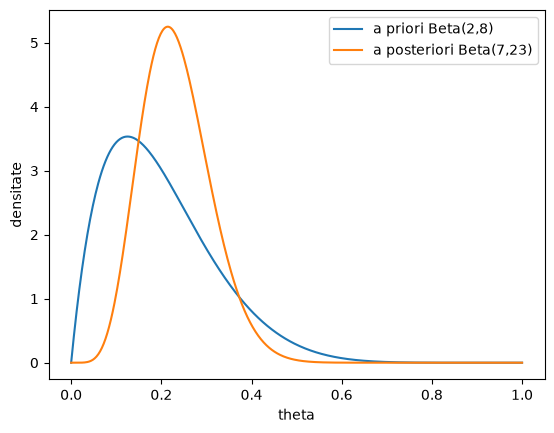

posterior (b): Beta(10, 35), media=0.2222
Posterior (c): Beta(5, 20), media=0.2000


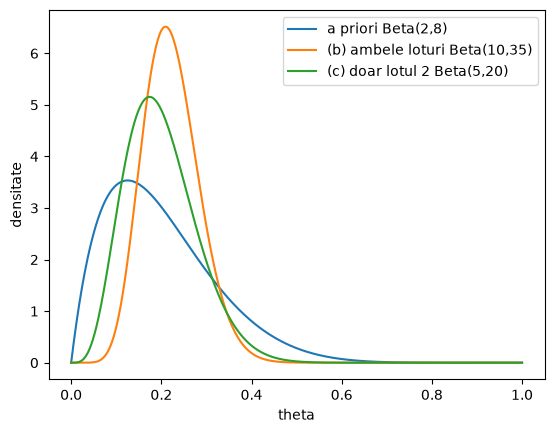

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

a0, b0=2, 8
x=np.linspace(0,1,500)

a1, b1= a0+5, b0+(20-5)
print(f"posterior (a): Beta({a1}, {b1}), media={a1/(a1 + b1):.4f}")
plt.plot(x, stats.beta.pdf(x, a0, b0), label="a priori Beta(2,8)")
plt.plot(x, stats.beta.pdf(x,a1, b1), label=f"a posteriori Beta({a1},{b1})")
plt.xlabel("theta"); plt.ylabel("densitate"); plt.legend(); plt.show()

a2, b2=a1+3, b1+(15-3)
print(f"posterior (b): Beta({a2}, {b2}), media={a2/(a2 + b2):.4f}")

a3, b3=a0+3, b0+(15-3)
print(f"Posterior (c): Beta({a3}, {b3}), media={a3/(a3 + b3):.4f}")

plt.plot(x, stats.beta.pdf(x, a0, b0), label="a priori Beta(2,8)")
plt.plot(x, stats.beta.pdf(x,a2,b2), label=f"(b) ambele loturi Beta({a2},{b2})")
plt.plot(x, stats.beta.pdf(x,a3,b3), label=f"(c) doar lotul 2 Beta({a3},{b3})")
plt.xlabel("theta"); plt.ylabel("densitate"); plt.legend(); plt.show()

Diferenta: (b) foloseste toate datele (5+3=8 defecte din 20+15=35 produse), deci distributia e mai ingusta si mai sigura. (c) ignora primul lot, se bazeaza doar pe 15 observatii si ramane mai aproape de prior.